In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

In [3]:
import json
from pathlib import Path

import dask
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr
from dask.diagnostics import ProgressBar

from cordex2energy.results.analysis import (
    compute_percentage_change,
    compute_seasonal_statistics,
    compute_sign_agreement,
    groupby_season,
)
from cordex2energy.results.plotting import (
    BLUE,
    RED,
    apply_land_mask,
    plot_ensemble_mean,
    plot_ensemble_mean_change,
    plot_ensemble_mean_change_seasonal,
    plot_ensemble_mean_seasonal,
    plot_percentage_change_spread,
    plot_yearly_timeseries_ensemble,
    plot_yearly_timeseries_ensemble_mean_range,
)
from cordex2energy.utils.constants import (
    EXTENT_BC,
    EXTENT_CH,
    IPCC_LINE_CHART_COLOR_PALETTE_HEX,
    MID_CENTURY_PERIOD,
    NEAR_FUTURE_PERIOD,
    REFERENCE_PERIOD,
)
from cordex2energy.utils.utils_xarray import sel_extent

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


In [4]:
paths = json.load(open("../../paths_so4.json"))

path_data_processed = Path(paths["path_data_processed"])
path_data_personal = Path(paths["path_data_personal"])
path_data_temporary = Path(paths["path_data_temporary"])

path_energy_ch = path_data_processed / "energy" / "seasonal" / "ch"
path_energy_europe = path_data_processed / "energy" / "seasonal" / "europe"
path_figs = Path(paths["path_figs"])

# Spatial extents
extent = {"lat_min": 33.5, "lat_max": 72.6, "lon_min": -12, "lon_max": 39}

# Turbine selection
europe_turbines = ["E-126/7580", "SWT120/3600", "SWT142/3150"]
ch_turbines = ["E-82/2300", "E-92/2350", "V90/2000", "V112/3300"]
selected_turbine = europe_turbines[0]
selected_turbine_ch = ch_turbines[0]
selected_pv_tilt_azimuth_ch = "tilt_35_azimuth_S"
climate_scenario = "rcp85"

# Season definitions
METEO_SEASONS = ["Winter", "Spring", "Summer", "Fall"]  # DJF, MAM, JJA, SON
ENERGY_SEASONS = ["Winter", "Summer"]  # ONDJFM, AMJJAS

SEASON_LABELS_METEO = {
    "Winter": "Winter (DJF)",
    "Spring": "Spring (MAM)",
    "Summer": "Summer (JJA)",
    "Fall": "Fall (SON)",
}
SEASON_LABELS_ENERGY = {
    "Winter": "Winter half-year (Oct–Mar)",
    "Summer": "Summer half-year (Apr–Sep)",
}

# Days per season — non-leap year (365 days total)
SEASON_DAYS_METEO = {
    "Winter": 90,  # DJF:    Dec(31) + Jan(31) + Feb(28)
    "Spring": 92,  # MAM:    Mar(31) + Apr(30) + May(31)
    "Summer": 92,  # JJA:    Jun(30) + Jul(31) + Aug(31)
    "Fall": 91,  # SON:    Sep(30) + Oct(31) + Nov(30)
}
SEASON_DAYS_ENERGY = {
    "Winter": 182,  # ONDJFM: Oct(31)+Nov(30)+Dec(31)+Jan(31)+Feb(28)+Mar(31)
    "Summer": 183,  # AMJJAS: Apr(30)+May(31)+Jun(30)+Jul(31)+Aug(31)+Sep(30)
}

In [5]:
dask.config.set(num_workers=15, threads_per_worker=16)
dask.config.set(
    {
        "distributed.worker.memory.target": 0.7,
        "distributed.worker.memory.spill": 0.8,
        "distributed.worker.memory.pause": 0.9,
        "array.chunk-size": "512MiB",
        "logging.distributed": "error",
    }
)

# Europe

## Load Seasonal Data

In [6]:
aggregation = "seasonal"  # "annual" or "seasonal"

### Meteorological seasons (DJF, MAM, JJA, SON)

In [7]:
season_type = "meteorological"  # "meteorological" or "energy"
time_resolution = "period"  # "yearly" or "period"
season_suffix = f"_{season_type}" if aggregation == "seasonal" else ""

In [8]:
# Load precomputed seasonal means for Europe — meteorological seasons
mean_ref_meteo = sel_extent(
    xr.open_dataset(
        path_data_processed
        / "energy"
        / "analysis"
        / aggregation
        / time_resolution
        / f"mean_reference_period{season_suffix}.nc"
    ),
    extent=extent,
)
mean_mid_century_meteo = sel_extent(
    xr.open_dataset(
        path_data_processed
        / "energy"
        / "analysis"
        / aggregation
        / time_resolution
        / f"mean_mid_century{season_suffix}.nc"
    ),
    extent=extent,
)
mean_ref_meteo["hydropower_ror"] = mean_ref_meteo["hydropower_ror"] * 1e-6
mean_mid_century_meteo["hydropower_ror"] = (
    mean_mid_century_meteo["hydropower_ror"] * 1e-6
)

print("Seasons:", mean_ref_meteo.season.values)
print("Models:", mean_ref_meteo.model.values)
print("Vars:", list(mean_ref_meteo.data_vars))

Seasons: ['Fall' 'Spring' 'Summer' 'Winter']
Models: ['CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85'
 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1_rcp85'
 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85'
 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1_rcp85']
Vars: ['pv', 'wind', 'hydropower_ror', 'hydropower_reservoir', 'CDD', 'HDD']


In [9]:
# Detect models with completely null data (any variable, any season)
null_models = []
for model in mean_ref_meteo.model.values:
    for var in mean_ref_meteo.data_vars:
        if mean_ref_meteo[var].sel(model=model).isnull().all():
            null_models.append((model, var))

if null_models:
    print("Models with null data (meteo):")
    for model, var in null_models:
        print(f"  {model}: {var}")
else:
    print("No models with completely null data found")

valid_models = [
    model
    for model in mean_mid_century_meteo.model.values
    if model not in [nm[0] for nm in null_models]
]

mean_ref_meteo = mean_ref_meteo.sel(model=valid_models)
mean_mid_century_meteo = mean_mid_century_meteo.sel(model=valid_models)

No models with completely null data found


In [10]:
# Apply land mask to 2D surface variables
for var in ["pv", "HDD", "CDD"]:
    mean_ref_meteo[var] = apply_land_mask(mean_ref_meteo[var])
    mean_mid_century_meteo[var] = apply_land_mask(mean_mid_century_meteo[var])

### Energy seasons (ONDJFM = Winter, AMJJAS = Summer)

In [11]:
# Load precomputed seasonal means for Europe — energy seasons
mean_ref_energy = sel_extent(
    xr.open_dataset(
        path_data_processed
        / "energy"
        / "analysis"
        / aggregation
        / time_resolution
        / "mean_reference_period_energy.nc"
    ),
    extent=extent,
)
mean_mid_century_energy = sel_extent(
    xr.open_dataset(
        path_data_processed
        / "energy"
        / "analysis"
        / aggregation
        / time_resolution
        / "mean_mid_century_energy.nc"
    ),
    extent=extent,
)
mean_ref_energy["hydropower_ror"] = mean_ref_energy["hydropower_ror"] * 1e-6
mean_mid_century_energy["hydropower_ror"] = (
    mean_mid_century_energy["hydropower_ror"] * 1e-6
)

# Apply land mask
for var in ["pv", "HDD", "CDD"]:
    mean_ref_energy[var] = apply_land_mask(mean_ref_energy[var])
    mean_mid_century_energy[var] = apply_land_mask(mean_mid_century_energy[var])

print("Seasons:", mean_ref_energy.season.values)
print("Models:", mean_ref_energy.model.values)
print("Vars:", list(mean_ref_energy.data_vars))

Seasons: ['Summer' 'Winter']
Models: ['CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85'
 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1_rcp85'
 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85'
 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1_rcp85']
Vars: ['pv', 'wind', 'hydropower_ror', 'hydropower_reservoir', 'CDD', 'HDD']


# Switzerland

## Load Seasonal Data

In [12]:
path_pv = path_data_processed / "energy" / "europe" / "pv"
path_pv_zarr = sorted(path_pv.glob(f"*/*{climate_scenario}*.zarr"))
data_var_pv = list(xr.open_zarr(path_pv_zarr[0], chunks="auto").data_vars.keys())[0]
ds_pv = sel_extent(
    xr.concat(
        [xr.open_zarr(path, chunks="auto") for path in path_pv_zarr], dim="model"
    ).rename({data_var_pv: "pv"}),
    extent=extent,
)
ds_pv["model"] = [path.stem.split("pv_")[1] for path in path_pv_zarr]

In [13]:
# Load precomputed seasonal means for Switzerland — meteorological seasons
mean_ref_meteo_ch = sel_extent(
    xr.open_dataset(
        path_data_processed
        / "energy"
        / "analysis"
        / aggregation
        / time_resolution
        / "mean_reference_period_ch_meteorological.nc"
    ),
    extent=EXTENT_CH,
)
mean_mid_century_meteo_ch = sel_extent(
    xr.open_dataset(
        path_data_processed
        / "energy"
        / "analysis"
        / aggregation
        / time_resolution
        / "mean_mid_century_ch_meteorological.nc"
    ),
    extent=EXTENT_CH,
)
mean_ref_meteo_ch["hydropower_ror"] = mean_ref_meteo_ch["hydropower_ror"] * 1e-6
mean_mid_century_meteo_ch["hydropower_ror"] = (
    mean_mid_century_meteo_ch["hydropower_ror"] * 1e-6
)

# Load precomputed seasonal means for Switzerland — energy seasons
mean_ref_energy_ch = sel_extent(
    xr.open_dataset(
        path_data_processed
        / "energy"
        / "analysis"
        / aggregation
        / time_resolution
        / "mean_reference_period_ch_energy.nc"
    ),
    extent=EXTENT_CH,
)
mean_mid_century_energy_ch = sel_extent(
    xr.open_dataset(
        path_data_processed
        / "energy"
        / "analysis"
        / aggregation
        / time_resolution
        / "mean_mid_century_ch_energy.nc"
    ),
    extent=EXTENT_CH,
)
mean_ref_energy_ch["hydropower_ror"] = mean_ref_energy_ch["hydropower_ror"] * 1e-6
mean_mid_century_energy_ch["hydropower_ror"] = (
    mean_mid_century_energy_ch["hydropower_ror"] * 1e-6
)

print("CH meteo seasons:", mean_ref_meteo_ch.season.values)
print("CH energy seasons:", mean_ref_energy_ch.season.values)

CH meteo seasons: ['Fall' 'Spring' 'Summer' 'Winter']
CH energy seasons: ['Summer' 'Winter']


In [14]:
# Load regional statistics (correctly computed seasonal time series for CH)
regional_stats_seasonal = xr.open_dataset(
    path_data_processed / "energy" / "ch" / "statistics" / "regional_stats_seasonal.nc"
)
print("Regional stats dims:", dict(regional_stats_seasonal.dims))
print("Masks:", regional_stats_seasonal.mask.values)
print("Models:", regional_stats_seasonal.model.values)
print("Vars:", list(regional_stats_seasonal.data_vars))
print("n_time:", len(regional_stats_seasonal.time))
print("Seasons on time axis:", np.unique(regional_stats_seasonal.season.values[:8]))

Regional stats dims: {'model': 9, 'time': 441, 'mask': 6}
Masks: ['Jura' 'Plateau' 'Pre-Alps' 'Alps' 'Southern Alps' 'Switzerland']
Models: ['CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85'
 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1_rcp85'
 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85'
 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1_rcp85'
 'MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1_rcp85']
Vars: ['pv', 'wind', 'hydropower_ror', 'hydropower_reservoir', 'CDD', 'HDD']
n_time: 441
Seasons on time axis: ['DJF' 'JJA' 'MAM' 'SON']


/tmp/ipykernel_111919/3340065963.py:5: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("Regional stats dims:", dict(regional_stats_seasonal.dims))


# Prepare data for plots

In [15]:
def _season_hours(ds, season_days):
    """Return a DataArray of hours per season aligned to ds.season coordinates."""
    return xr.DataArray(
        [season_days[s] * 24 for s in ds.season.values],
        coords={"season": ds.season.values},
        dims=["season"],
    )


_ENERGY_SCALE = {"pv": 100, "wind": 100, "hydropower_ror": 1}

# ── Europe — meteorological seasons ──────────────────────────────────────────
mean_ref_meteo_plot = mean_ref_meteo.copy()
_h = _season_hours(mean_ref_meteo_plot, SEASON_DAYS_METEO)
for var, factor in _ENERGY_SCALE.items():
    if var in mean_ref_meteo_plot.data_vars:
        mean_ref_meteo_plot[var] = mean_ref_meteo_plot[var] * factor * _h * 1e-3

mean_mid_century_meteo_plot = mean_mid_century_meteo.copy()
_h = _season_hours(mean_mid_century_meteo_plot, SEASON_DAYS_METEO)
for var, factor in _ENERGY_SCALE.items():
    if var in mean_mid_century_meteo_plot.data_vars:
        mean_mid_century_meteo_plot[var] = (
            mean_mid_century_meteo_plot[var] * factor * _h * 1e-3
        )

# ── Europe — energy seasons ────────────────────────────────────────────────────
mean_ref_energy_plot = mean_ref_energy.copy()
_h = _season_hours(mean_ref_energy_plot, SEASON_DAYS_ENERGY)
for var, factor in _ENERGY_SCALE.items():
    if var in mean_ref_energy_plot.data_vars:
        mean_ref_energy_plot[var] = mean_ref_energy_plot[var] * factor * _h * 1e-3

mean_mid_century_energy_plot = mean_mid_century_energy.copy()
_h = _season_hours(mean_mid_century_energy_plot, SEASON_DAYS_ENERGY)
for var, factor in _ENERGY_SCALE.items():
    if var in mean_mid_century_energy_plot.data_vars:
        mean_mid_century_energy_plot[var] = (
            mean_mid_century_energy_plot[var] * factor * _h * 1e-3
        )

# ── Switzerland — meteorological seasons ──────────────────────────────────────
mean_ref_meteo_ch_plot = mean_ref_meteo_ch.copy()
_h = _season_hours(mean_ref_meteo_ch_plot, SEASON_DAYS_METEO)
for var, factor in _ENERGY_SCALE.items():
    if var in mean_ref_meteo_ch_plot.data_vars:
        mean_ref_meteo_ch_plot[var] = mean_ref_meteo_ch_plot[var] * factor * _h * 1e-3

# ── Switzerland — energy seasons ──────────────────────────────────────────────
mean_ref_energy_ch_plot = mean_ref_energy_ch.copy()
_h = _season_hours(mean_ref_energy_ch_plot, SEASON_DAYS_ENERGY)
for var, factor in _ENERGY_SCALE.items():
    if var in mean_ref_energy_ch_plot.data_vars:
        mean_ref_energy_ch_plot[var] = mean_ref_energy_ch_plot[var] * factor * _h * 1e-3

# Europe

## Percentage Change Spread

In [16]:
components_size_config = {
    "FONTSIZE_LEGEND": 6,
    "FONTSIZE_TICKS": 6,
    "FONTSIZE_LABELS": 7,
    "FONTSIZE_TITLE": 10,
    "MARKER_SIZE": 4,
    "BAR_HEIGHT": 0.35,
    "BBOX_TO_ANCHOR": (0.5, -0.05),
}

### Meteorological Seasons

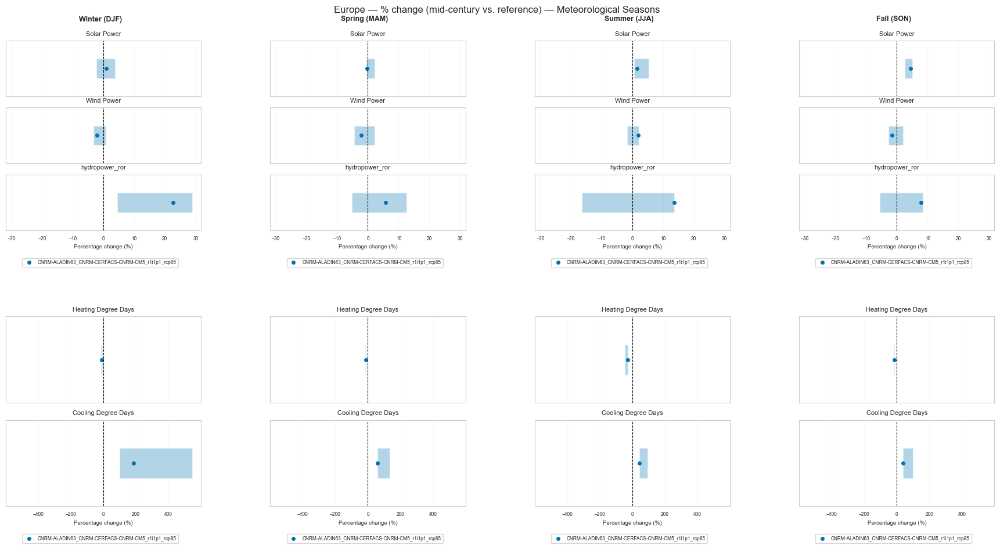

In [17]:
var_groups = {
    "renewables": ["pv", "wind", "hydropower_ror", "hydropower_reservoirs"],
    "demand": ["HDD", "CDD"],
}

# Pre-check which vars are available per group (using first season as reference)
_ref_check = mean_ref_meteo.sel(season=METEO_SEASONS[0])
group_available_vars = {
    group_name: [v for v in vars_in_group if v in _ref_check.data_vars]
    for group_name, vars_in_group in var_groups.items()
}

# Pre-compute a shared x-axis limit per group across ALL seasons
group_xlim = {}
for group_name, group_vars in group_available_vars.items():
    all_pct = []
    for season in METEO_SEASONS:
        ref_s = mean_ref_meteo.sel(season=season)
        future_s = mean_mid_century_meteo.sel(season=season)
        for var in group_vars:
            for model in valid_models:
                ref_val = ref_s[var].sel(model=model).mean(dim=["lat", "lon"]).values
                mid_val = future_s[var].sel(model=model).mean(dim=["lat", "lon"]).values
                if not (np.isnan(ref_val) or np.isnan(mid_val)) and ref_val != 0:
                    all_pct.append((mid_val - ref_val) / ref_val * 100)
    group_xlim[group_name] = np.max(np.abs(all_pct)) * 1.1 if all_pct else 10

n_groups = len(var_groups)
n_seasons = len(METEO_SEASONS)

# Figure: rows = groups, columns = seasons; subfigures keep each cell's axes independent
fig = plt.figure(
    figsize=(n_seasons * 4.5, sum(len(v) for v in group_available_vars.values()) * 1.8)
)
subfigs = fig.subfigures(n_groups, n_seasons, squeeze=False, hspace=0.12, wspace=0.05)

for row_idx, (group_name, _) in enumerate(var_groups.items()):
    group_vars = group_available_vars[group_name]
    if not group_vars:
        continue

    xlim = group_xlim[group_name]

    for col_idx, season in enumerate(METEO_SEASONS):
        ref_s = mean_ref_meteo.sel(season=season)
        future_s = mean_mid_century_meteo.sel(season=season)

        sfig = subfigs[row_idx, col_idx]

        # Season label as column header (top row only)
        if row_idx == 0:
            sfig.suptitle(SEASON_LABELS_METEO[season], fontsize=9, fontweight="bold")

        axes = sfig.subplots(len(group_vars), 1, sharex=True)
        if len(group_vars) == 1:
            axes = [axes]

        plot_percentage_change_spread(
            ref_s,
            future_s,
            variables=group_vars,
            valid_models=valid_models,
            selected_model="CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85",
            color=BLUE,
            components_size_config=components_size_config,
            bar_alpha=0.3,
            ax=axes,
        )

        # Override with the group-wide shared x-axis limit
        for a in axes:
            a.set_xlim(-xlim, xlim)

fig.suptitle(
    "Europe — % change (mid-century vs. reference) — Meteorological Seasons",
    fontsize=12,
    y=1.01,
)
plt.show()

### Energy Seasons

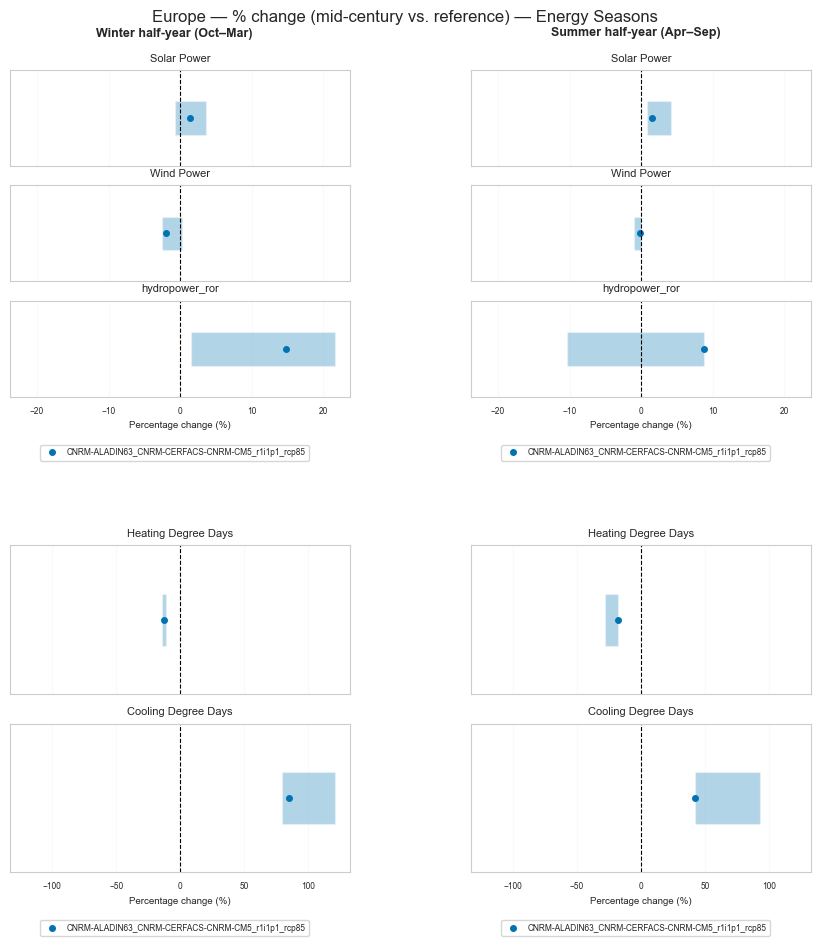

In [18]:
# Pre-check which vars are available per group (using first energy season as reference)
_ref_check_energy = mean_ref_energy.sel(season=ENERGY_SEASONS[0])
group_available_vars_energy = {
    group_name: [v for v in vars_in_group if v in _ref_check_energy.data_vars]
    for group_name, vars_in_group in var_groups.items()
}

# Pre-compute a shared x-axis limit per group across ALL energy seasons
energy_valid_models = mean_ref_energy.model.values.tolist()
group_xlim_energy = {}
for group_name, group_vars in group_available_vars_energy.items():
    all_pct = []
    for season in ENERGY_SEASONS:
        ref_s = mean_ref_energy.sel(season=season)
        future_s = mean_mid_century_energy.sel(season=season)
        for var in group_vars:
            for model in energy_valid_models:
                ref_val = ref_s[var].sel(model=model).mean(dim=["lat", "lon"]).values
                mid_val = future_s[var].sel(model=model).mean(dim=["lat", "lon"]).values
                if not (np.isnan(ref_val) or np.isnan(mid_val)) and ref_val != 0:
                    all_pct.append((mid_val - ref_val) / ref_val * 100)
    group_xlim_energy[group_name] = np.max(np.abs(all_pct)) * 1.1 if all_pct else 10

n_groups = len(var_groups)
n_seasons = len(ENERGY_SEASONS)

fig = plt.figure(
    figsize=(
        n_seasons * 4.5,
        sum(len(v) for v in group_available_vars_energy.values()) * 1.8,
    )
)
subfigs = fig.subfigures(n_groups, n_seasons, squeeze=False, hspace=0.12, wspace=0.05)

for row_idx, (group_name, _) in enumerate(var_groups.items()):
    group_vars = group_available_vars_energy[group_name]
    if not group_vars:
        continue

    xlim = group_xlim_energy[group_name]

    for col_idx, season in enumerate(ENERGY_SEASONS):
        ref_s = mean_ref_energy.sel(season=season)
        future_s = mean_mid_century_energy.sel(season=season)

        sfig = subfigs[row_idx, col_idx]

        # Season label as column header (top row only)
        if row_idx == 0:
            sfig.suptitle(SEASON_LABELS_ENERGY[season], fontsize=9, fontweight="bold")

        axes = sfig.subplots(len(group_vars), 1, sharex=True)
        if len(group_vars) == 1:
            axes = [axes]

        plot_percentage_change_spread(
            ref_s,
            future_s,
            variables=group_vars,
            valid_models=energy_valid_models,
            selected_model="CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85",
            color=BLUE,
            components_size_config=components_size_config,
            bar_alpha=0.3,
            ax=axes,
        )

        # Override with the group-wide shared x-axis limit
        for a in axes:
            a.set_xlim(-xlim, xlim)

fig.suptitle(
    "Europe — % change (mid-century vs. reference) — Energy Seasons",
    fontsize=12,
    y=1.01,
)
plt.show()

## Ensemble Mean Maps

In [19]:
var_titles = {
    "pv": "Solar Power Potential",
    "wind": "Wind Power Potential",
    "hydropower_ror": "RoR Hydropower Potential",
    # "hydropower_reservoir": "Reservoir Hydropower Inflows",
    "HDD": "Heating Degree Days",
    "CDD": "Cooling Degree Days",
}
var_clabel = {
    "pv": "Generation (GWh)",
    "wind": "Generation (GWh)",
    "hydropower_ror": "Generation (GWh)",
    "HDD": "Degree-Days",
    "CDD": "Degree-Days",
}

component_sizes_ensemble_mean_europe = {
    "FONTSIZE_LEGEND": 18,
    "FONTSIZE_TICKS": 16,
    "FONTSIZE_LABELS": 19,
    "FONTSIZE_TITLE": 22,
    "CBAR_SHRINK": 0.75,
    "CBAR_ASPECT": 15,
    "CBAR_PAD": 0.03,
}

component_sizes_ensemble_mean_europe_poster = {
    "FONTSIZE_LEGEND": 9,
    "FONTSIZE_TICKS": 11,
    "FONTSIZE_LABELS": 12,
    "FONTSIZE_TITLE": 12,
    "CBAR_SHRINK": 0.75,
    "CBAR_ASPECT": 15,
    "CBAR_PAD": 0.03,
}

# Grid layout: rows = variables, columns = seasons.
# CBAR_WIDTH: colorbar column width as a fraction of a map column.
# HSPACE / WSPACE: vertical / horizontal gap between subplots (in fraction of axes height/width).
component_sizes_ensemble_mean_seasonal = {
    "FONTSIZE_LEGEND": 10,
    "FONTSIZE_TICKS": 10,
    "FONTSIZE_LABELS": 12,
    "FONTSIZE_TITLE": 14,
    "CBAR_WIDTH": 0.05,
    "CBAR_PAD": 0.02,
    "HSPACE": 0.08,
    "WSPACE": 0.0,
    "SUPTITLE_Y": 0.9,
}

### Meteorological Seasons (Reference Period)

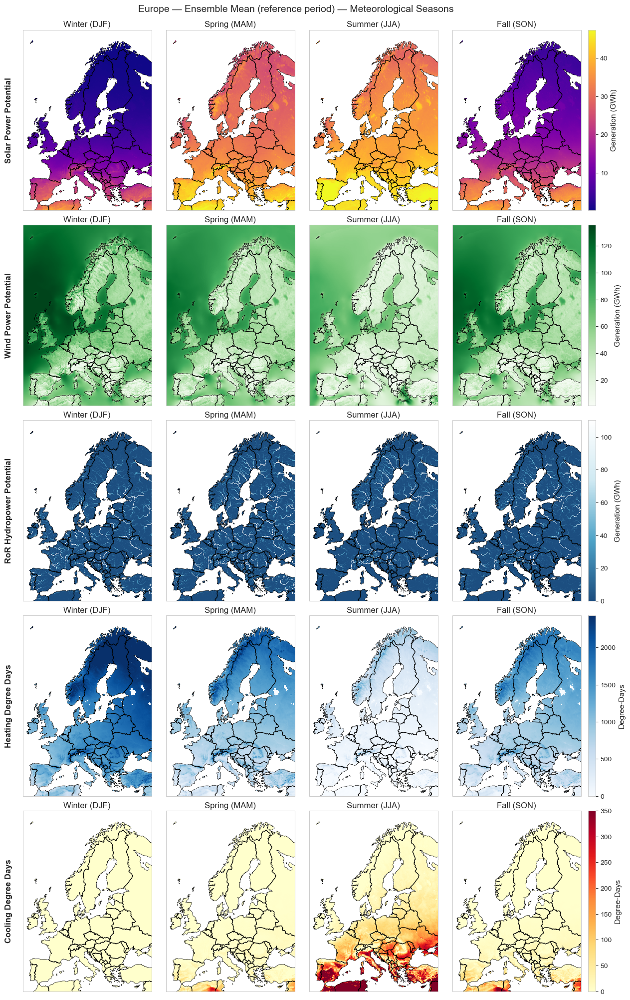

In [20]:
available_vars = [v for v in var_titles if v in mean_ref_meteo_plot.data_vars]

plot_ensemble_mean_seasonal(
    mean_ref_meteo_plot[available_vars],
    seasons=METEO_SEASONS,
    season_labels=SEASON_LABELS_METEO,
    var_titles=var_titles,
    var_clabel=var_clabel,
    figsize=(15, 25),
    components_size_config=component_sizes_ensemble_mean_seasonal,
    title="Europe — Ensemble Mean (reference period) — Meteorological Seasons",
    path_savefig=path_figs / "energy" / "seasonal" / "mean_ref_europe_meteo_seasonal.png",
)

### Energy Seasons (Reference Period)

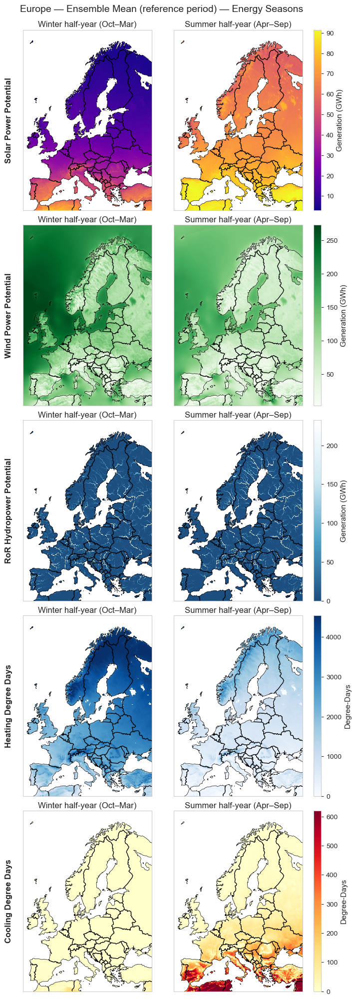

In [21]:
available_vars_energy = [v for v in var_titles if v in mean_ref_energy_plot.data_vars]

plot_ensemble_mean_seasonal(
    mean_ref_energy_plot[available_vars_energy],
    seasons=ENERGY_SEASONS,
    season_labels=SEASON_LABELS_ENERGY,
    var_titles=var_titles,
    var_clabel=var_clabel,
    figsize=(8, 25),
    components_size_config=component_sizes_ensemble_mean_seasonal,
    title="Europe — Ensemble Mean (reference period) — Energy Seasons",
    path_savefig=path_figs / "energy" / "seasonal" / "mean_ref_europe_energy_seasonal.png",
)

### Energy Seasons (Reference Period) — Transposed Layout (seasons as rows, variables as columns)

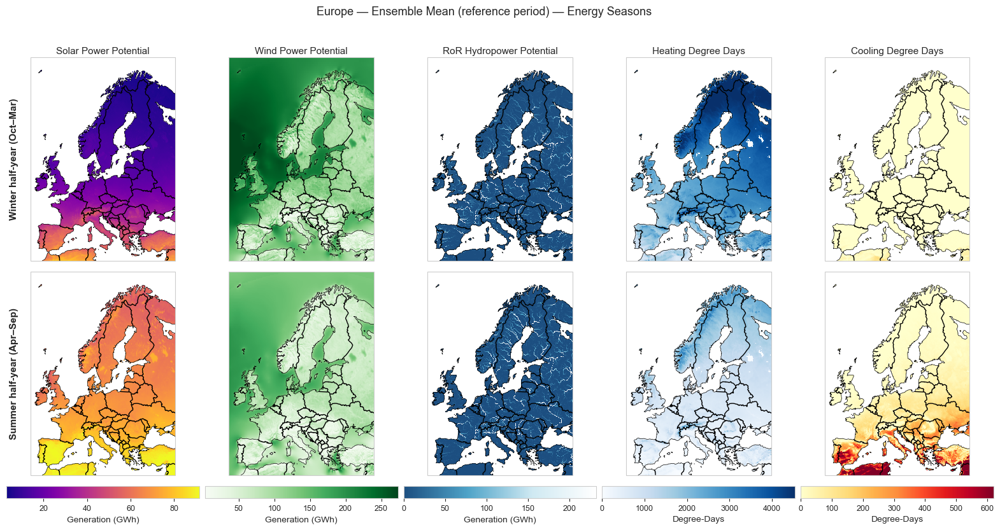

In [22]:
component_sizes_ensemble_mean_seasonal_transposed = {
    "FONTSIZE_LEGEND": 10,
    "FONTSIZE_TICKS": 9,
    "FONTSIZE_LABELS": 11,
    "FONTSIZE_TITLE": 13,
    "CBAR_WIDTH": 0.02,   # colorbar column width (default layout, unused here)
    "CBAR_HEIGHT": 0.06,  # colorbar row height fraction (transposed layout)
    "CBAR_PAD": 0.02,
    "HSPACE": 0.08,
    "WSPACE": 0.03,
    "SUPTITLE_Y": 0.97,
}

plot_ensemble_mean_seasonal(
    mean_ref_energy_plot[available_vars_energy],
    seasons=ENERGY_SEASONS,
    season_labels=SEASON_LABELS_ENERGY,
    var_titles=var_titles,
    var_clabel=var_clabel,
    figsize=(20, 9),
    components_size_config=component_sizes_ensemble_mean_seasonal_transposed,
    title="Europe — Ensemble Mean (reference period) — Energy Seasons",
    path_savefig=path_figs / "energy" / "seasonal" / "mean_ref_europe_energy_seasonal_transposed.png",
    transpose=True,
)

## Ensemble Mean Change Maps

### Meteorological Seasons

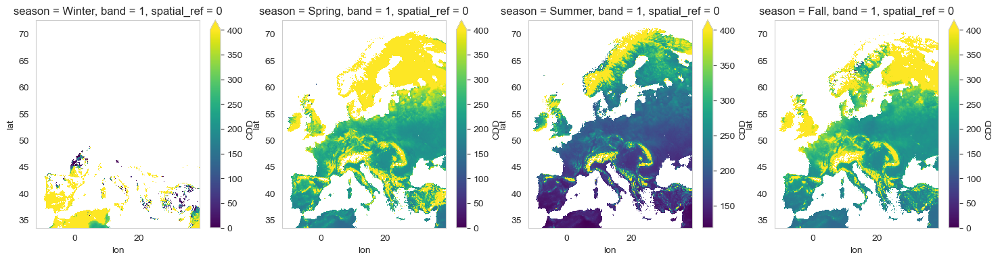

In [23]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for i, season in enumerate(METEO_SEASONS):
    (
        mean_mid_century_meteo_plot["CDD"].mean("model")
        / (mean_ref_meteo_plot["CDD"].mean("model"))
        * 100
    ).sel(season=season).plot(ax=ax[i], vmax=400)

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


{'pv': -16.8309375, 'wind': -16.8309375, 'hydropower_ror': -46.50065555555547, 'hydropower_reservoir': None, 'HDD': -39.048166666666674, 'CDD': -93.19566666666667}
{'pv': 16.8309375, 'wind': 16.8309375, 'hydropower_ror': 46.50065555555547, 'hydropower_reservoir': None, 'HDD': 39.048166666666674, 'CDD': 93.19566666666667}


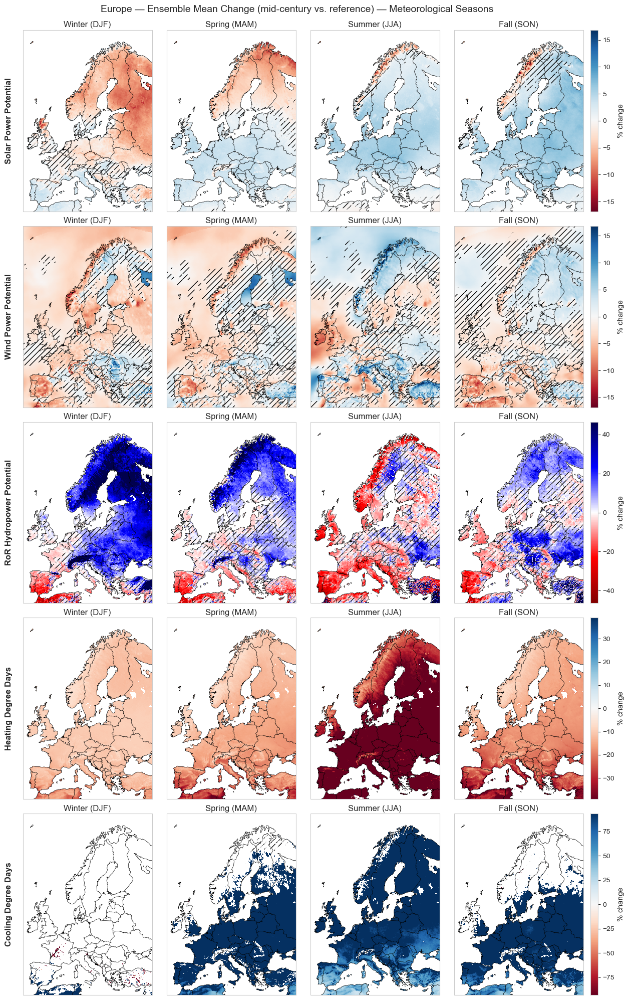

In [24]:
change_vars = [
    v
    for v in var_titles
    if v in mean_ref_meteo.data_vars and v in mean_mid_century_meteo.data_vars
]

plot_ensemble_mean_change_seasonal(
    mean_ref_meteo_plot[change_vars],
    mean_mid_century_meteo_plot[change_vars],
    absolute_change=False,
    seasons=METEO_SEASONS,
    season_labels=SEASON_LABELS_METEO,
    var_titles=var_titles,
    var_clabel={v: "% change" for v in change_vars},
    figsize=(15, 25),
    components_size_config=component_sizes_ensemble_mean_seasonal,
    # mask_insignificant=True,
    title="Europe — Ensemble Mean Change (mid-century vs. reference) — Meteorological Seasons",
    path_savefig=path_figs
    / "energy"
    / "seasonal"
    / "mean_percentage_change_europe_meteo_seasonal.png",
)

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


{'pv': -6.68206720003262, 'wind': -6.68206720003262, 'hydropower_ror': -6.68206720003262, 'hydropower_reservoir': None, 'HDD': -220.05670362124644, 'CDD': -68.60134912543033}
{'pv': 6.68206720003262, 'wind': 6.68206720003262, 'hydropower_ror': 6.68206720003262, 'hydropower_reservoir': None, 'HDD': 220.05670362124644, 'CDD': 68.60134912543033}


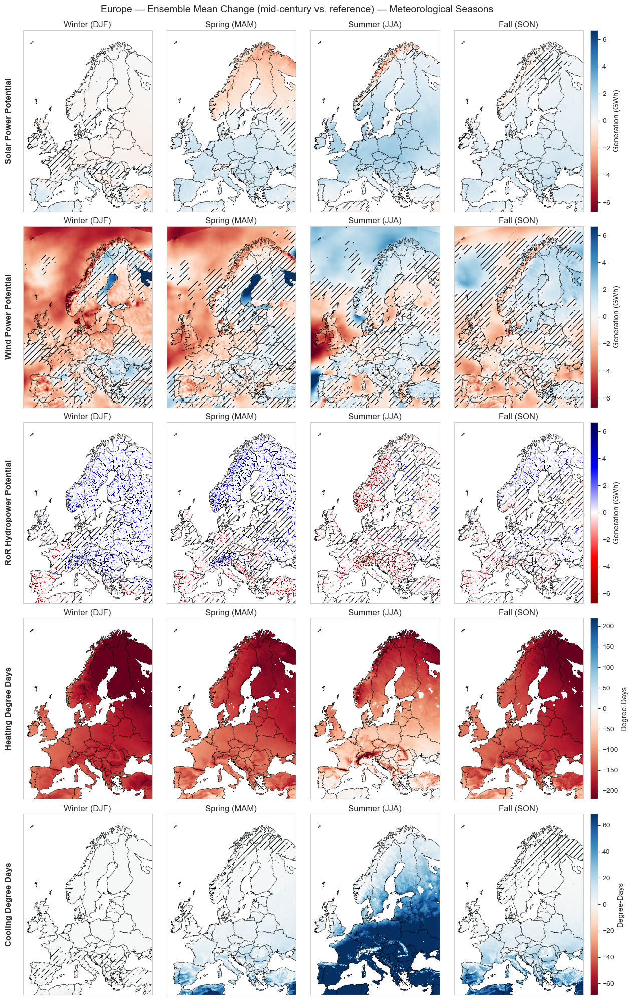

In [25]:
change_vars = [
    v
    for v in var_titles
    if v in mean_ref_meteo.data_vars and v in mean_mid_century_meteo.data_vars
]

plot_ensemble_mean_change_seasonal(
    mean_ref_meteo_plot[change_vars],
    mean_mid_century_meteo_plot[change_vars],
    absolute_change=True,
    seasons=METEO_SEASONS,
    season_labels=SEASON_LABELS_METEO,
    var_titles=var_titles,
    # var_clabel={v: "% change" for v in change_vars},
    var_clabel=var_clabel,
    figsize=(15, 25),
    components_size_config=component_sizes_ensemble_mean_seasonal,
    # mask_insignificant=True,
    title="Europe — Ensemble Mean Change (mid-century vs. reference) — Meteorological Seasons",
    path_savefig=path_figs
    / "energy"
    / "seasonal"
    / "mean_absolute_change_europe_meteo_seasonal.png",
)

## Ensemble Mean Change Maps — Energy Seasons

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


{'pv': -13.126362399643794, 'wind': -13.126362399643794, 'hydropower_ror': -13.126362399643794, 'hydropower_reservoir': None, 'HDD': -449.8713730330543, 'CDD': -136.6617856955554}
{'pv': 13.126362399643794, 'wind': 13.126362399643794, 'hydropower_ror': 13.126362399643794, 'hydropower_reservoir': None, 'HDD': 449.8713730330543, 'CDD': 136.6617856955554}


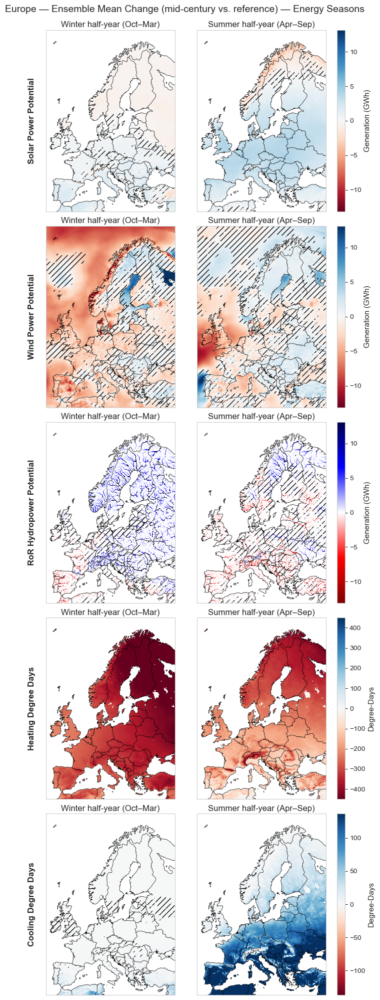

In [26]:
change_vars_energy = [
    v
    for v in var_titles
    if v in mean_ref_energy.data_vars and v in mean_mid_century_energy.data_vars
]

plot_ensemble_mean_change_seasonal(
    mean_ref_energy_plot[change_vars_energy],
    mean_mid_century_energy_plot[change_vars_energy],
    absolute_change=True,
    seasons=ENERGY_SEASONS,
    season_labels=SEASON_LABELS_ENERGY,
    var_titles=var_titles,
    var_clabel=var_clabel,
    # var_clabel={v: "% change" for v in change_vars_energy},
    figsize=(8, 25),
    components_size_config=component_sizes_ensemble_mean_seasonal,
    # mask_insignificant=True,
    title="Europe — Ensemble Mean Change (mid-century vs. reference) — Energy Seasons",
    path_savefig=path_figs / "energy" / "seasonal" / "mean_absolute_change_europe_energy_seasonal.png",
)

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


{'pv': -16.8775, 'wind': -16.8775, 'hydropower_ror': -36.14208888888886, 'hydropower_reservoir': None, 'HDD': -29.332888888888885, 'CDD': -74.53816666666667}
{'pv': 16.8775, 'wind': 16.8775, 'hydropower_ror': 36.14208888888886, 'hydropower_reservoir': None, 'HDD': 29.332888888888885, 'CDD': 74.53816666666667}


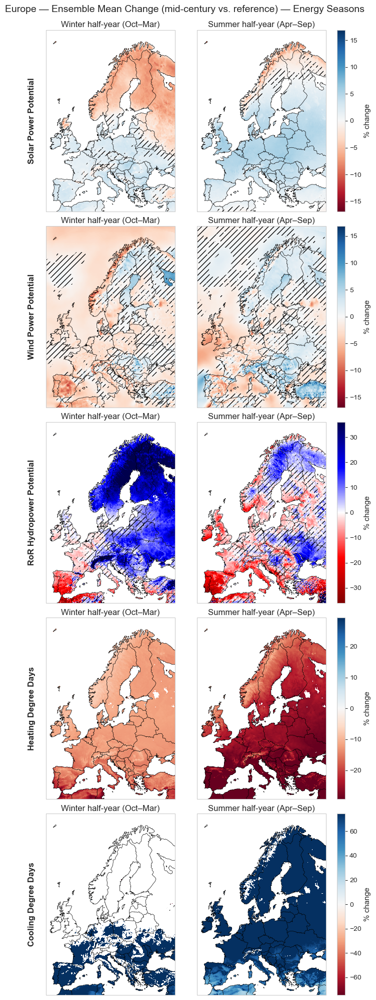

In [27]:
change_vars_energy = [
    v
    for v in var_titles
    if v in mean_ref_energy.data_vars and v in mean_mid_century_energy.data_vars
]

plot_ensemble_mean_change_seasonal(
    mean_ref_energy_plot[change_vars_energy],
    mean_mid_century_energy_plot[change_vars_energy],
    absolute_change=False,
    seasons=ENERGY_SEASONS,
    season_labels=SEASON_LABELS_ENERGY,
    var_titles=var_titles,
    # var_clabel=var_clabel,
    var_clabel={v: "% change" for v in change_vars_energy},
    figsize=(8, 25),
    components_size_config=component_sizes_ensemble_mean_seasonal,
    # mask_insignificant=True,
    title="Europe — Ensemble Mean Change (mid-century vs. reference) — Energy Seasons",
    path_savefig=path_figs / "energy" / "seasonal" / "mean_percentage_change_europe_energy_seasonal.png",
)

### Ensemble Mean Change Maps — Energy Seasons — Transposed Layout

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


{'pv': -16.8775, 'wind': -16.8775, 'hydropower_ror': -36.14208888888886, 'hydropower_reservoir': None, 'HDD': -29.332888888888885, 'CDD': -74.53816666666667}
{'pv': 16.8775, 'wind': 16.8775, 'hydropower_ror': 36.14208888888886, 'hydropower_reservoir': None, 'HDD': 29.332888888888885, 'CDD': 74.53816666666667}


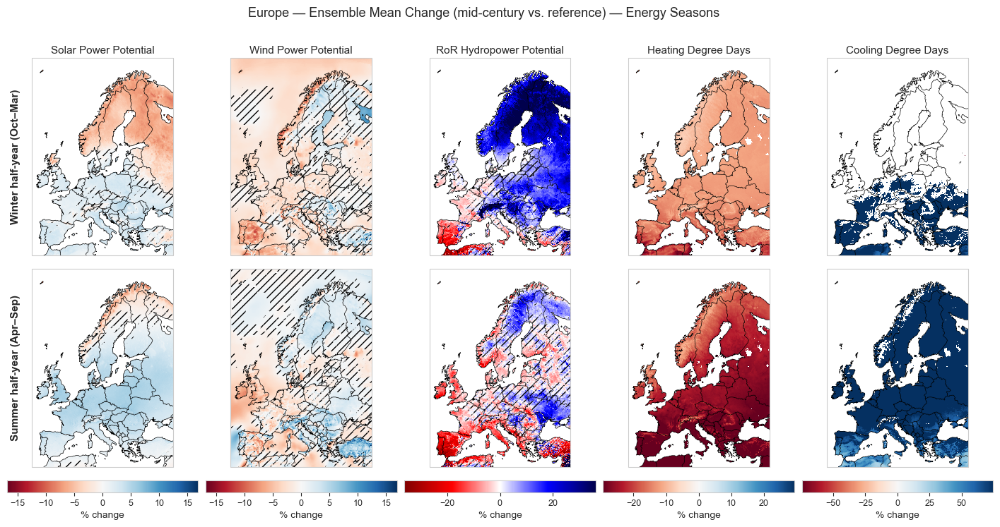

In [28]:
component_sizes_change_seasonal_transposed = {
    "FONTSIZE_TICKS": 9,
    "FONTSIZE_LABELS": 11,
    "FONTSIZE_TITLE": 13,
    "CBAR_HEIGHT": 0.06,  # colorbar row height fraction (transposed layout)
    "CBAR_PAD": 0.02,
    "HSPACE": 0.10,
    "WSPACE": 0.04,
    "SUPTITLE_Y": 0.97,
}

plot_ensemble_mean_change_seasonal(
    mean_ref_energy_plot[change_vars_energy],
    mean_mid_century_energy_plot[change_vars_energy],
    absolute_change=False,
    seasons=ENERGY_SEASONS,
    season_labels=SEASON_LABELS_ENERGY,
    var_titles=var_titles,
    var_clabel={v: "% change" for v in change_vars_energy},
    figsize=(18, 8),
    components_size_config=component_sizes_change_seasonal_transposed,
    title="Europe — Ensemble Mean Change (mid-century vs. reference) — Energy Seasons",
    path_savefig=path_figs / "energy" / "seasonal" / "mean_percentage_change_europe_energy_seasonal_transposed.png",
    transpose=True,
)

# Switzerland

## Percentage Change Spread — Meteorological Seasons

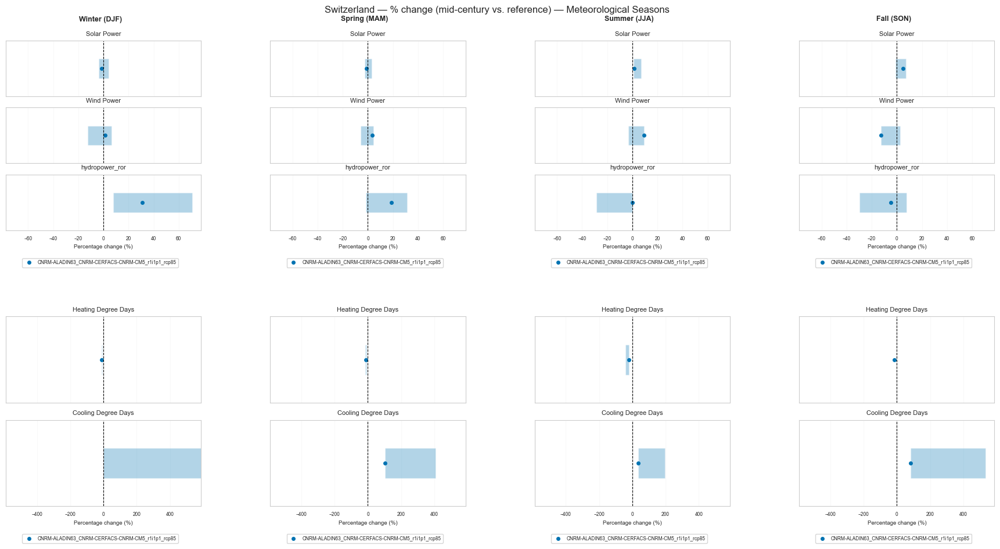

In [31]:
ch_meteo_valid_models = mean_ref_meteo_ch.model.values.tolist()

# Pre-check which vars are available per group (using first season as reference)
_ref_check_ch = mean_ref_meteo_ch.sel(season=METEO_SEASONS[0])
group_available_vars_ch = {
    group_name: [v for v in vars_in_group if v in _ref_check_ch.data_vars]
    for group_name, vars_in_group in var_groups.items()
}

# Pre-compute a shared x-axis limit per group across ALL seasons
group_xlim_ch = {}
for group_name, group_vars in group_available_vars_ch.items():
    all_pct = []
    for season in METEO_SEASONS:
        ref_s = mean_ref_meteo_ch.sel(season=season)
        future_s = mean_mid_century_meteo_ch.sel(season=season)
        for var in group_vars:
            for model in ch_meteo_valid_models:
                ref_val = ref_s[var].sel(model=model).mean(dim=["lat", "lon"]).values
                mid_val = future_s[var].sel(model=model).mean(dim=["lat", "lon"]).values
                if not (np.isnan(ref_val) or np.isnan(mid_val)) and ref_val != 0:
                    all_pct.append((mid_val - ref_val) / ref_val * 100)
    group_xlim_ch[group_name] = np.max(np.abs(all_pct)) * 1.1 if all_pct else 10

n_groups = len(var_groups)
n_seasons = len(METEO_SEASONS)

fig = plt.figure(
    figsize=(
        n_seasons * 4.5,
        sum(len(v) for v in group_available_vars_ch.values()) * 1.8,
    )
)
subfigs = fig.subfigures(n_groups, n_seasons, squeeze=False, hspace=0.12, wspace=0.05)

for row_idx, (group_name, _) in enumerate(var_groups.items()):
    group_vars = group_available_vars_ch[group_name]
    if not group_vars:
        continue

    xlim = group_xlim_ch[group_name]

    for col_idx, season in enumerate(METEO_SEASONS):
        ref_s = mean_ref_meteo_ch.sel(season=season)
        future_s = mean_mid_century_meteo_ch.sel(season=season)

        sfig = subfigs[row_idx, col_idx]

        if row_idx == 0:
            sfig.suptitle(SEASON_LABELS_METEO[season], fontsize=9, fontweight="bold")

        axes = sfig.subplots(len(group_vars), 1, sharex=True)
        if len(group_vars) == 1:
            axes = [axes]

        plot_percentage_change_spread(
            ref_s+1e-5,
            future_s+1e-5,
            variables=group_vars,
            valid_models=ch_meteo_valid_models,
            selected_model="CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85",
            color=BLUE,
            components_size_config=components_size_config,
            bar_alpha=0.3,
            ax=axes,
        )

        for a in axes:
            a.set_xlim(-xlim, xlim)

fig.suptitle(
    "Switzerland — % change (mid-century vs. reference) — Meteorological Seasons",
    fontsize=12,
    y=1.01,
)
plt.show()

## Percentage Change Spread — Energy Seasons

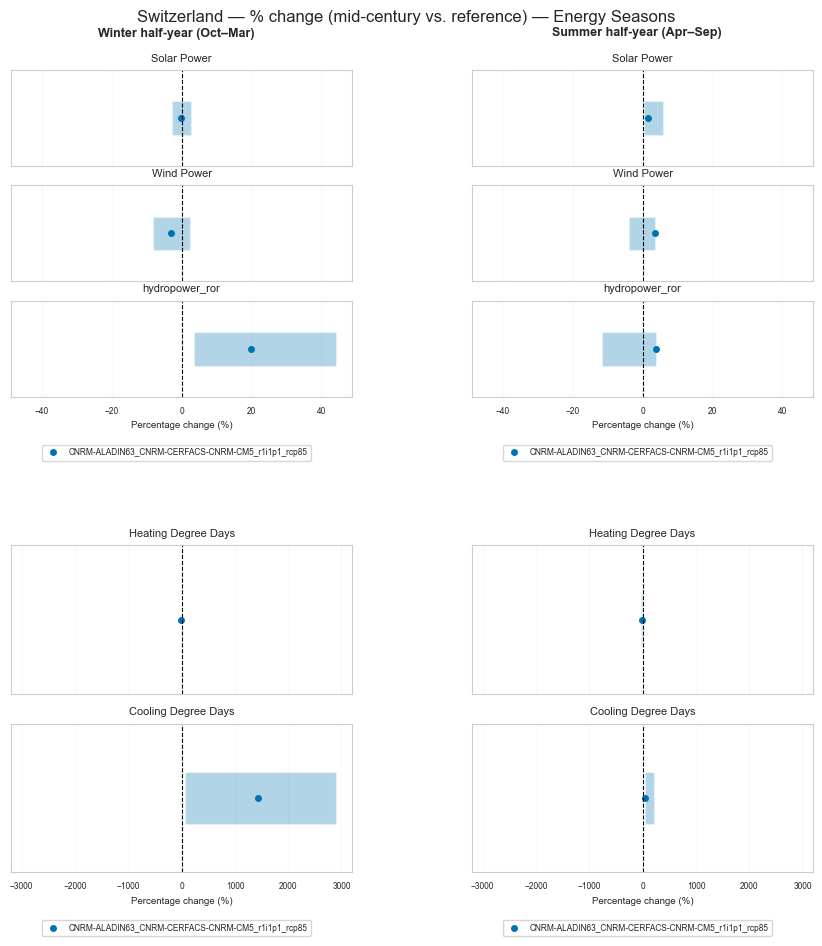

In [32]:
ch_energy_valid_models = mean_ref_energy_ch.model.values.tolist()

# Pre-check which vars are available per group (using first energy season as reference)
_ref_check_energy_ch = mean_ref_energy_ch.sel(season=ENERGY_SEASONS[0])
group_available_vars_energy_ch = {
    group_name: [v for v in vars_in_group if v in _ref_check_energy_ch.data_vars]
    for group_name, vars_in_group in var_groups.items()
}

# Pre-compute a shared x-axis limit per group across ALL energy seasons
group_xlim_energy_ch = {}
for group_name, group_vars in group_available_vars_energy_ch.items():
    all_pct = []
    for season in ENERGY_SEASONS:
        ref_s = mean_ref_energy_ch.sel(season=season)
        future_s = mean_mid_century_energy_ch.sel(season=season)
        for var in group_vars:
            for model in ch_energy_valid_models:
                ref_val = ref_s[var].sel(model=model).mean(dim=["lat", "lon"]).values
                mid_val = future_s[var].sel(model=model).mean(dim=["lat", "lon"]).values
                if not (np.isnan(ref_val) or np.isnan(mid_val)) and ref_val != 0:
                    all_pct.append((mid_val - ref_val) / ref_val * 100)
    group_xlim_energy_ch[group_name] = np.max(np.abs(all_pct)) * 1.1 if all_pct else 10

n_groups = len(var_groups)
n_seasons = len(ENERGY_SEASONS)

fig = plt.figure(
    figsize=(
        n_seasons * 4.5,
        sum(len(v) for v in group_available_vars_energy_ch.values()) * 1.8,
    )
)
subfigs = fig.subfigures(n_groups, n_seasons, squeeze=False, hspace=0.12, wspace=0.05)

for row_idx, (group_name, _) in enumerate(var_groups.items()):
    group_vars = group_available_vars_energy_ch[group_name]
    if not group_vars:
        continue

    xlim = group_xlim_energy_ch[group_name]

    for col_idx, season in enumerate(ENERGY_SEASONS):
        ref_s = mean_ref_energy_ch.sel(season=season)
        future_s = mean_mid_century_energy_ch.sel(season=season)

        sfig = subfigs[row_idx, col_idx]

        if row_idx == 0:
            sfig.suptitle(SEASON_LABELS_ENERGY[season], fontsize=9, fontweight="bold")

        axes = sfig.subplots(len(group_vars), 1, sharex=True)
        if len(group_vars) == 1:
            axes = [axes]

        plot_percentage_change_spread(
            ref_s + 1e-5,
            future_s + 1e-5,
            variables=group_vars,
            valid_models=ch_energy_valid_models,
            selected_model="CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85",
            color=BLUE,
            components_size_config=components_size_config,
            bar_alpha=0.3,
            ax=axes,
        )

        for a in axes:
            a.set_xlim(-xlim, xlim)

fig.suptitle(
    "Switzerland — % change (mid-century vs. reference) — Energy Seasons",
    fontsize=12,
    y=1.01,
)
plt.show()

## Ensemble Mean Maps — Switzerland — Meteorological Seasons (Reference Period)

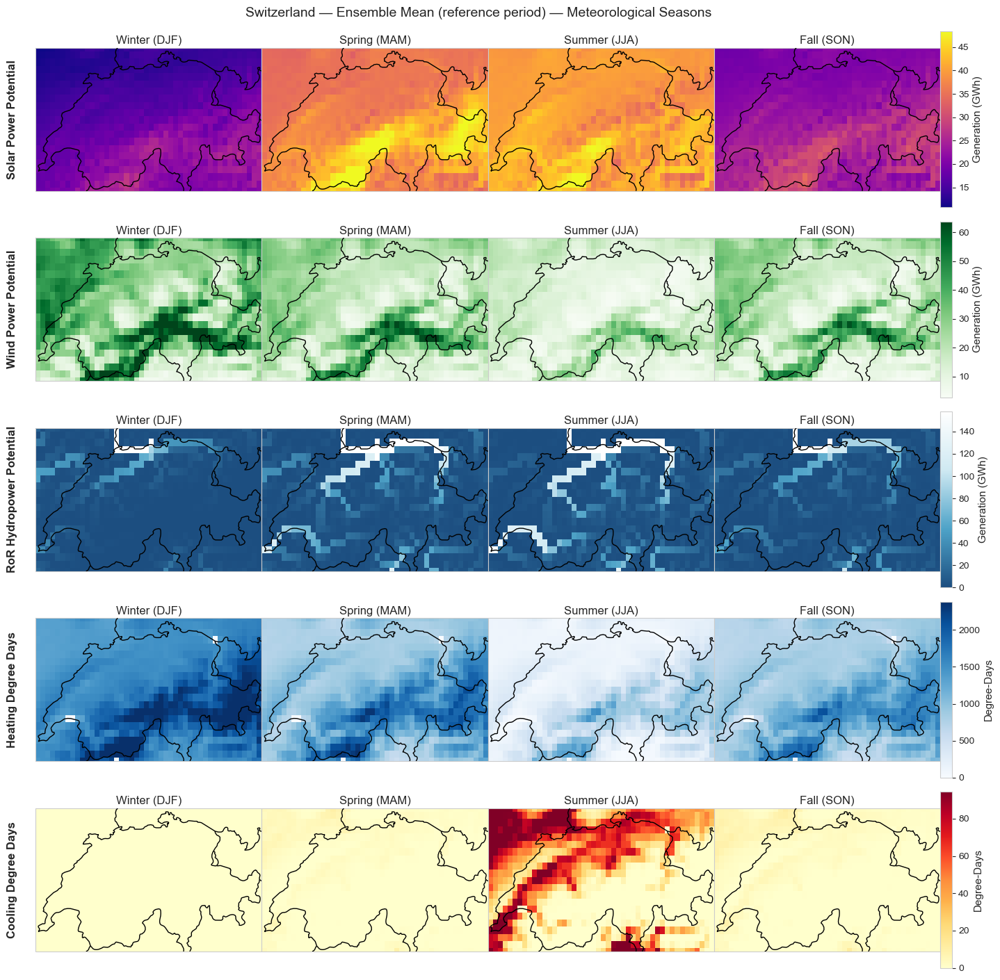

In [33]:
available_vars_ch = [v for v in var_titles if v in mean_ref_meteo_ch_plot.data_vars]

plot_ensemble_mean_seasonal(
    mean_ref_meteo_ch_plot[available_vars_ch],
    seasons=METEO_SEASONS,
    season_labels=SEASON_LABELS_METEO,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_seasonal,
    title="Switzerland — Ensemble Mean (reference period) — Meteorological Seasons",
    # path_savefig=path_figs / "energy" / "seasonal" / "mean_ref_ch_meteo_seasonal.png",
)

## Ensemble Mean Maps — Switzerland — Energy Seasons (Reference Period)

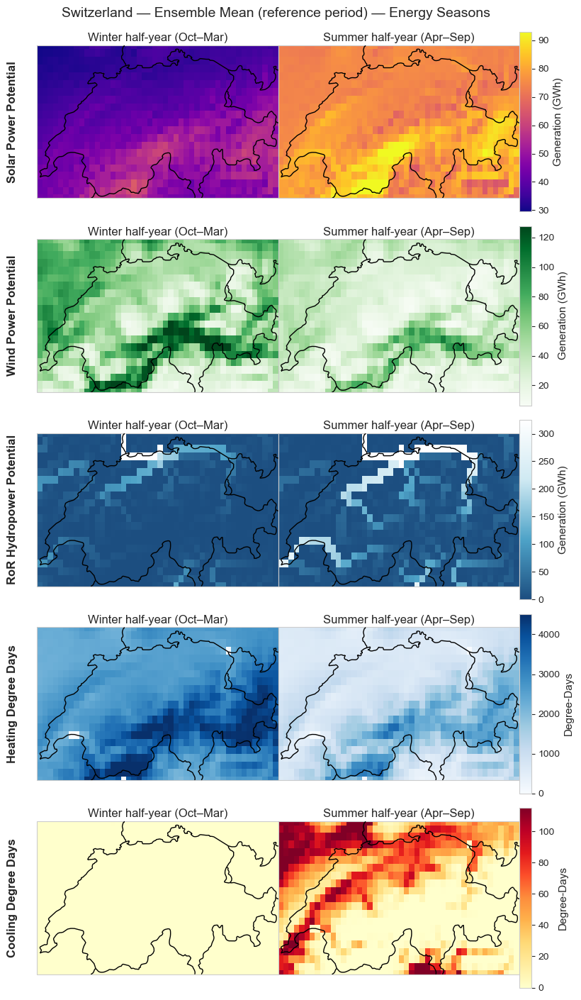

In [34]:
available_vars_energy_ch = [
    v for v in var_titles if v in mean_ref_energy_ch_plot.data_vars
]

plot_ensemble_mean_seasonal(
    mean_ref_energy_ch_plot[available_vars_energy_ch],
    seasons=ENERGY_SEASONS,
    season_labels=SEASON_LABELS_ENERGY,
    var_titles=var_titles,
    var_clabel=var_clabel,
    components_size_config=component_sizes_ensemble_mean_seasonal,
    title="Switzerland — Ensemble Mean (reference period) — Energy Seasons",
    # path_savefig=path_figs / "energy" / "seasonal" / "mean_ref_ch_energy_seasonal.png",
)

## Ensemble Mean Change Maps — Switzerland — Meteorological Seasons

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


{'pv': -7.466944444444444, 'wind': -7.466944444444444, 'hydropower_ror': -48.114900000000006, 'hydropower_reservoir': None, 'HDD': -27.142958333333336, 'CDD': -175.34246296296297}
{'pv': 7.466944444444444, 'wind': 7.466944444444444, 'hydropower_ror': 48.114900000000006, 'hydropower_reservoir': None, 'HDD': 27.142958333333336, 'CDD': 175.34246296296297}


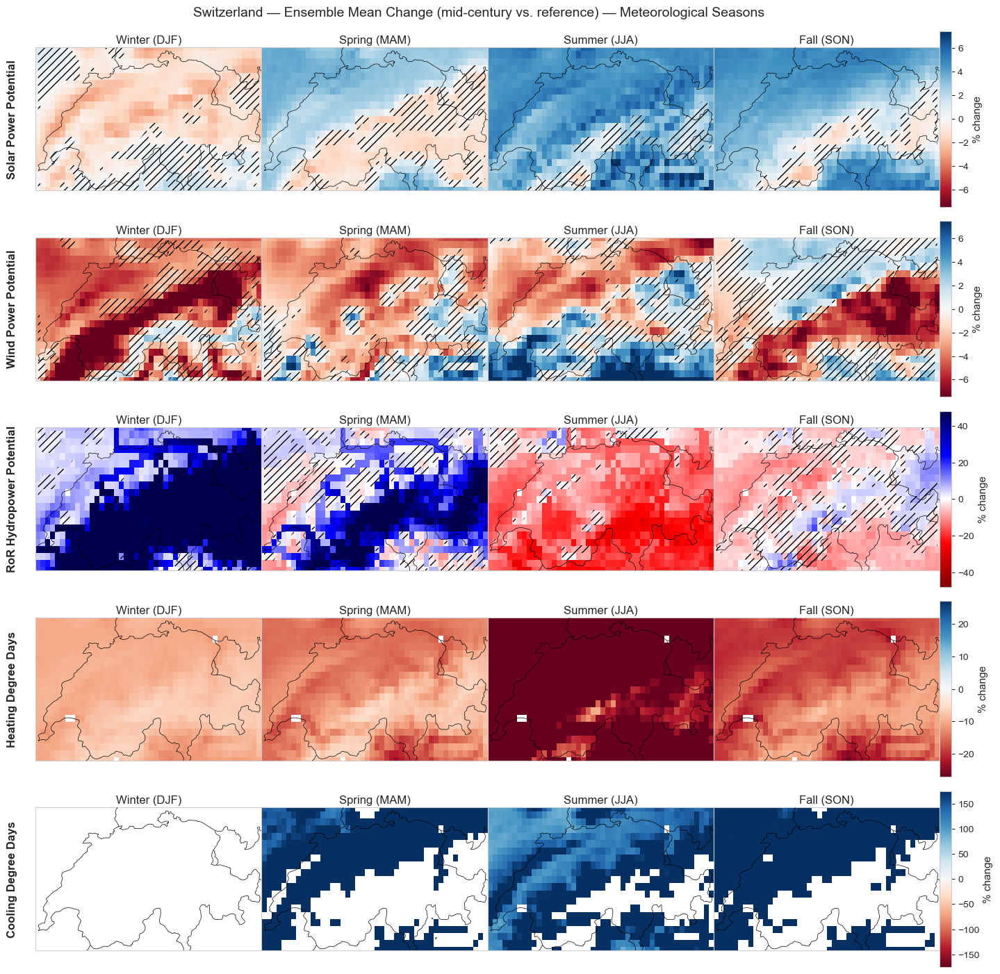

In [39]:
change_vars_ch = [
    v
    for v in var_titles
    if v in mean_ref_meteo_ch.data_vars and v in mean_mid_century_meteo_ch.data_vars
]

plot_ensemble_mean_change_seasonal(
    mean_ref_meteo_ch[change_vars_ch],
    mean_mid_century_meteo_ch[change_vars_ch],
    seasons=METEO_SEASONS,
    season_labels=SEASON_LABELS_METEO,
    var_titles=var_titles,
    var_clabel={v: "% change" for v in change_vars_ch},
    components_size_config=component_sizes_ensemble_mean_seasonal,
    mask_insignificant=False,
    title="Switzerland — Ensemble Mean Change (mid-century vs. reference) — Meteorological Seasons",
    # path_savefig=path_figs / "energy" / "seasonal" / "mean_change_ch_meteo_seasonal.png",
)

## Ensemble Mean Change Maps — Switzerland — Energy Seasons

/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/ClimateScenarios4Energy-CH/cordex2energy/results/analysis.py:288: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


{'pv': -8.101111111111111, 'wind': -8.101111111111111, 'hydropower_ror': -34.31544444444445, 'hydropower_reservoir': None, 'HDD': -21.73561111111111, 'CDD': -339.74791666666664}
{'pv': 8.101111111111111, 'wind': 8.101111111111111, 'hydropower_ror': 34.31544444444445, 'hydropower_reservoir': None, 'HDD': 21.73561111111111, 'CDD': 339.74791666666664}


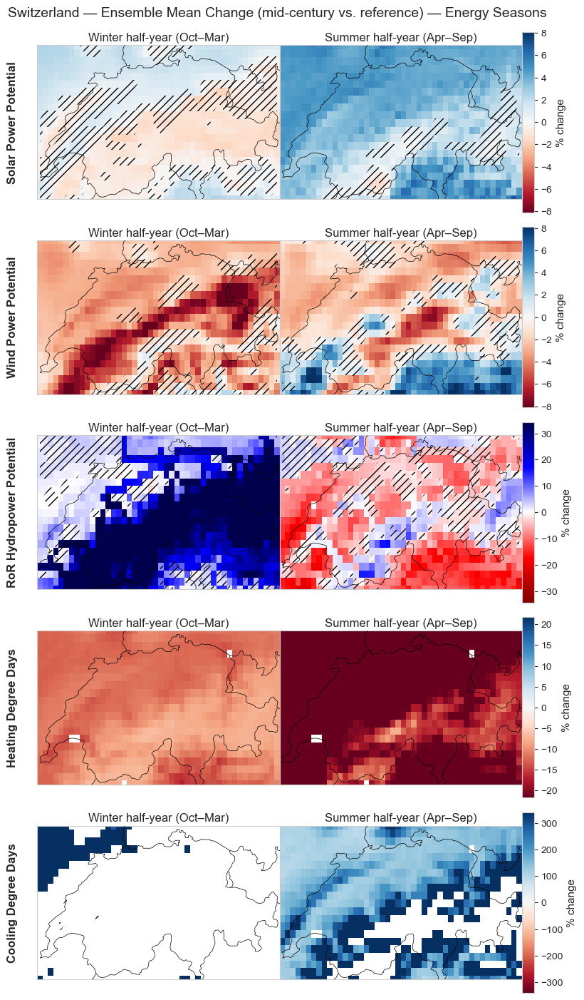

In [43]:
change_vars_energy_ch = [
    v
    for v in var_titles
    if v in mean_ref_energy_ch.data_vars and v in mean_mid_century_energy_ch.data_vars
]

plot_ensemble_mean_change_seasonal(
    mean_ref_energy_ch[change_vars_energy_ch],
    mean_mid_century_energy_ch[change_vars_energy_ch],
    seasons=ENERGY_SEASONS,
    season_labels=SEASON_LABELS_ENERGY,
    var_titles=var_titles,
    var_clabel={v: "% change" for v in change_vars_energy_ch},
    components_size_config=component_sizes_ensemble_mean_seasonal,
    mask_insignificant=False,
    title="Switzerland — Ensemble Mean Change (mid-century vs. reference) — Energy Seasons",
    # path_savefig=path_figs / "energy" / "seasonal" / "mean_change_ch_energy_seasonal.png",
)

# Regional Seasonal Time Series (Switzerland)

Using `regional_stats_seasonal.nc` which contains correctly identified seasonal time series for each CH region/mask.
The `season` coordinate on the time axis identifies the season for each time step.

In [44]:
# Helper: select one season from the regional_stats_seasonal dataset
def select_season_ts(ds, season_name):
    """Return time steps belonging to the given season label."""
    mask = ds.season == season_name
    return ds.isel(time=mask.values)

## Meteorological Season Time Series

In [45]:
ts_vars = ["pv", "wind_onshore", "hydropower_ror", "HDD", "CDD"]
mask_label = regional_stats_seasonal.mask.values[0]  # use first mask by default

for season in METEO_SEASONS:
    ds_s = select_season_ts(regional_stats_seasonal, season)
    for var in ts_vars:
        if var not in ds_s.data_vars:
            continue
        da = ds_s[var].sel(mask=mask_label)

        fig = plot_yearly_timeseries_ensemble_mean_range(
            da,
            title=f"CH — {SEASON_LABELS_METEO[season]} — {var}",
            ylabel=var,
        )
        fig.savefig(
            path_figs
            / "energy"
            / "seasonal"
            / f"timeseries_{var}_ch_{season.lower()}_meteo.png",
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

TypeError: plot_yearly_timeseries_ensemble_mean_range() got an unexpected keyword argument 'ylabel'

## Energy Season Time Series

In [ ]:
for season in ENERGY_SEASONS:
    ds_s = select_season_ts(regional_stats_seasonal, season)
    for var in ts_vars:
        if var not in ds_s.data_vars:
            continue
        da = ds_s[var].sel(mask=mask_label)

        fig = plot_yearly_timeseries_ensemble_mean_range(
            da,
            title=f"CH — {SEASON_LABELS_ENERGY[season]} — {var}",
            ylabel=var,
        )
        fig.savefig(
            path_figs
            / "energy"
            / "seasonal"
            / f"timeseries_{var}_ch_{season.lower()}_energy.png",
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

## All Masks — Ensemble Mean and Range per Season

Plot time series for every available regional mask.

In [ ]:
all_masks = regional_stats_seasonal.mask.values

for season in METEO_SEASONS:
    ds_s = select_season_ts(regional_stats_seasonal, season)
    for var in ts_vars:
        if var not in ds_s.data_vars:
            continue
        fig, axes = plt.subplots(
            1, len(all_masks), figsize=(5 * len(all_masks), 4), sharey=True
        )
        if len(all_masks) == 1:
            axes = [axes]
        for ax, msk in zip(axes, all_masks):
            da = ds_s[var].sel(mask=msk)
            ensemble_mean = da.mean(dim="model")
            ensemble_p10 = da.quantile(0.1, dim="model")
            ensemble_p90 = da.quantile(0.9, dim="model")
            years = ds_s.year.values
            ax.fill_between(years, ensemble_p10, ensemble_p90, alpha=0.3)
            ax.plot(years, ensemble_mean, lw=2)
            ax.set_title(str(msk))
            ax.set_xlabel("Year")
        axes[0].set_ylabel(var)
        fig.suptitle(
            f"CH — {SEASON_LABELS_METEO[season]} — {var} — all masks",
            fontsize=12,
        )
        plt.tight_layout()
        fig.savefig(
            path_figs
            / "energy"
            / "seasonal"
            / f"timeseries_{var}_ch_all_masks_{season.lower()}_meteo.png",
            dpi=150,
            bbox_inches="tight",
        )
        plt.show()
        plt.close(fig)

# HDD / CDD Seasonal Analysis

## Heating vs Cooling Degree Days by Season

In [ ]:
# HDD/CDD ensemble mean per meteorological season — regional (first mask)
hdd_cdd_vars = ["HDD", "CDD"]

fig, axes = plt.subplots(
    len(hdd_cdd_vars),
    len(METEO_SEASONS),
    figsize=(5 * len(METEO_SEASONS), 4 * len(hdd_cdd_vars)),
    sharey="row",
)

for row_idx, var in enumerate(hdd_cdd_vars):
    for col_idx, season in enumerate(METEO_SEASONS):
        ax = axes[row_idx, col_idx]
        if var not in regional_stats_seasonal.data_vars:
            ax.set_visible(False)
            continue
        ds_s = select_season_ts(regional_stats_seasonal, season)
        da = ds_s[var].sel(mask=mask_label)
        ensemble_mean = da.mean(dim="model")
        ensemble_p10 = da.quantile(0.1, dim="model")
        ensemble_p90 = da.quantile(0.9, dim="model")
        years = ds_s.year.values
        ax.fill_between(years, ensemble_p10, ensemble_p90, alpha=0.3)
        ax.plot(years, ensemble_mean, lw=2)
        ax.set_title(f"{SEASON_LABELS_METEO[season]}")
        ax.set_xlabel("Year")
        if col_idx == 0:
            ax.set_ylabel(var)

fig.suptitle(
    f"CH — HDD & CDD — Meteorological Seasons — mask: {mask_label}", fontsize=13
)
plt.tight_layout()
fig.savefig(
    path_figs / "energy" / "seasonal" / f"hdd_cdd_seasonal_meteo_ch_{mask_label}.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

In [ ]:
# Seasonal mean HDD & CDD — reference vs. mid-century (bar comparison)
season_order = METEO_SEASONS

hdd_ref = []
hdd_fut = []
cdd_ref = []
cdd_fut = []

for season in season_order:
    ds_ref_s = select_season_ts(regional_stats_seasonal, season)
    # Reference period: 1981–2010 ≈ years <= 2010
    ref_years_mask = ds_ref_s.year.values <= 2010
    fut_years_mask = (ds_ref_s.year.values >= 2041) & (ds_ref_s.year.values <= 2070)

    def _mean_over_period(var, year_mask):
        da = ds_ref_s[var].sel(mask=mask_label).isel(time=year_mask)
        return float(da.mean(dim=["time", "model"]).values)

    hdd_ref.append(
        _mean_over_period("HDD", ref_years_mask)
        if "HDD" in ds_ref_s.data_vars
        else np.nan
    )
    hdd_fut.append(
        _mean_over_period("HDD", fut_years_mask)
        if "HDD" in ds_ref_s.data_vars
        else np.nan
    )
    cdd_ref.append(
        _mean_over_period("CDD", ref_years_mask)
        if "CDD" in ds_ref_s.data_vars
        else np.nan
    )
    cdd_fut.append(
        _mean_over_period("CDD", fut_years_mask)
        if "CDD" in ds_ref_s.data_vars
        else np.nan
    )

x = np.arange(len(season_order))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(x - width / 2, hdd_ref, width, label="Reference (1981–2010)")
ax1.bar(x + width / 2, hdd_fut, width, label="Mid-century (2041–2070)")
ax1.set_xticks(x)
ax1.set_xticklabels([SEASON_LABELS_METEO[s] for s in season_order])
ax1.set_ylabel("HDD [°C·days]")
ax1.set_title(f"HDD by season — CH ({mask_label})")
ax1.legend()

ax2.bar(x - width / 2, cdd_ref, width, label="Reference (1981–2010)")
ax2.bar(x + width / 2, cdd_fut, width, label="Mid-century (2041–2070)")
ax2.set_xticks(x)
ax2.set_xticklabels([SEASON_LABELS_METEO[s] for s in season_order])
ax2.set_ylabel("CDD [°C·days]")
ax2.set_title(f"CDD by season — CH ({mask_label})")
ax2.legend()

plt.tight_layout()
fig.savefig(
    path_figs / "energy" / "seasonal" / f"hdd_cdd_bar_seasonal_ch_{mask_label}.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

# Theil-Sen Seasonal Trend Analysis

Compute the Theil-Sen slope for each variable, season, and model over the regional time series.
This quantifies the trend per decade for each seasonal signal.

In [ ]:
def compute_theilsen_seasonal(ds, season_name, var, mask_val):
    """
    Compute the Theil-Sen slope [units/decade] per model for a given season
    using the regional_stats_seasonal dataset.
    """
    ds_s = select_season_ts(ds, season_name)
    da = ds_s[var].sel(mask=mask_val)
    years = ds_s.year.values.astype(float)

    slopes = []
    for model in da.model.values:
        y = da.sel(model=model).values
        valid = ~np.isnan(y)
        if valid.sum() < 3:
            slopes.append(np.nan)
            continue
        res = scipy.stats.theilslopes(y[valid], years[valid])
        slopes.append(res.slope * 10)  # per decade

    return np.array(slopes), da.model.values


theilsen_results = {}
for season in METEO_SEASONS + ENERGY_SEASONS:
    season_type = "meteo" if season in METEO_SEASONS else "energy"
    for var in ts_vars:
        if var not in regional_stats_seasonal.data_vars:
            continue
        try:
            slopes, models = compute_theilsen_seasonal(
                regional_stats_seasonal, season, var, mask_label
            )
            theilsen_results[(season, var)] = {"slopes": slopes, "models": models}
        except Exception as e:
            print(f"Skipping {season}/{var}: {e}")

In [ ]:
## Plot Theil-Sen slopes as box-whisker per variable and season

# Meteorological seasons
for var in ts_vars:
    keys = [(s, var) for s in METEO_SEASONS if (s, var) in theilsen_results]
    if not keys:
        continue

    data_by_season = [theilsen_results[k]["slopes"] for k in keys]
    labels = [SEASON_LABELS_METEO[k[0]] for k in keys]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.boxplot(
        [d[~np.isnan(d)] for d in data_by_season],
        labels=labels,
        notch=False,
        patch_artist=True,
        medianprops={"color": "black", "lw": 2},
    )
    ax.axhline(0, color="gray", lw=1, ls="--")
    ax.set_ylabel(f"Theil-Sen slope [units/decade]")
    ax.set_title(f"CH — {var} — seasonal trend (Theil-Sen) — {mask_label}")
    plt.tight_layout()
    fig.savefig(
        path_figs
        / "energy"
        / "seasonal"
        / f"theilsen_{var}_ch_meteo_seasons_{mask_label}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

In [ ]:
# Energy seasons — Theil-Sen boxplots
for var in ts_vars:
    keys = [(s, var) for s in ENERGY_SEASONS if (s, var) in theilsen_results]
    if not keys:
        continue

    data_by_season = [theilsen_results[k]["slopes"] for k in keys]
    labels = [SEASON_LABELS_ENERGY[k[0]] for k in keys]

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.boxplot(
        [d[~np.isnan(d)] for d in data_by_season],
        labels=labels,
        notch=False,
        patch_artist=True,
        medianprops={"color": "black", "lw": 2},
    )
    ax.axhline(0, color="gray", lw=1, ls="--")
    ax.set_ylabel(f"Theil-Sen slope [units/decade]")
    ax.set_title(f"CH — {var} — energy-season trend (Theil-Sen) — {mask_label}")
    plt.tight_layout()
    fig.savefig(
        path_figs
        / "energy"
        / "seasonal"
        / f"theilsen_{var}_ch_energy_seasons_{mask_label}.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

## Summary Heatmap — Ensemble-Median Theil-Sen Slope (Meteorological Seasons)

In [ ]:
import pandas as pd

rows = []
for season in METEO_SEASONS:
    row = {"Season": SEASON_LABELS_METEO[season]}
    for var in ts_vars:
        key = (season, var)
        if key in theilsen_results:
            slopes = theilsen_results[key]["slopes"]
            row[var] = round(float(np.nanmedian(slopes)), 4)
        else:
            row[var] = np.nan
    rows.append(row)

df_ts = pd.DataFrame(rows).set_index("Season")

fig, ax = plt.subplots(figsize=(len(ts_vars) * 2, len(METEO_SEASONS) * 1.2))
im = ax.imshow(
    df_ts.values.astype(float),
    aspect="auto",
    cmap="RdBu_r",
)
ax.set_xticks(range(len(df_ts.columns)))
ax.set_xticklabels(df_ts.columns, rotation=45, ha="right")
ax.set_yticks(range(len(df_ts.index)))
ax.set_yticklabels(df_ts.index)
plt.colorbar(im, ax=ax, label="Theil-Sen slope [units/decade]")
ax.set_title(
    f"Ensemble-Median Theil-Sen Slope — CH — Meteorological Seasons\n(mask: {mask_label})"
)

# Annotate cells
for i in range(len(df_ts.index)):
    for j in range(len(df_ts.columns)):
        val = df_ts.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=8)

plt.tight_layout()
fig.savefig(
    path_figs / "energy" / "seasonal" / f"theilsen_heatmap_meteo_ch_{mask_label}.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()
df_ts